In [1]:
import torch
from torchvision import datasets, transforms

In [2]:
# 1. Définir la transformation pour convertir les images en tenseurs
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # Normalisation standard pour MNIST
])

# 2. Télécharger et charger le jeu d'entraînement
train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

# 3. Télécharger et charger le jeu de test
test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

print(f"Jeu d'entraînement chargé : {len(train_dataset)} images")
print(f"Jeu de test chargé : {len(test_dataset)} images")

100%|██████████| 9.91M/9.91M [00:00<00:00, 37.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.22MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.78MB/s]

Jeu d'entraînement chargé : 60000 images
Jeu de test chargé : 10000 images


In [3]:
!ls -lrt data/MNIST/raw/

total 65008
-rw-r--r-- 1 root root  9912422 Nov 17 14:57 train-images-idx3-ubyte.gz
-rw-r--r-- 1 root root 47040016 Nov 17 14:57 train-images-idx3-ubyte
-rw-r--r-- 1 root root    28881 Nov 17 14:57 train-labels-idx1-ubyte.gz
-rw-r--r-- 1 root root    60008 Nov 17 14:57 train-labels-idx1-ubyte
-rw-r--r-- 1 root root  1648877 Nov 17 14:57 t10k-images-idx3-ubyte.gz
-rw-r--r-- 1 root root  7840016 Nov 17 14:57 t10k-images-idx3-ubyte
-rw-r--r-- 1 root root     4542 Nov 17 14:57 t10k-labels-idx1-ubyte.gz
-rw-r--r-- 1 root root    10008 Nov 17 14:57 t10k-labels-idx1-ubyte


In [4]:
import numpy as np
import os

def load_mnist_images(filename):
    with open(filename, 'rb') as f:
        # Les 4 premiers entiers (magic number, nombre d'images, lignes, colonnes)
        magic, num, rows, cols = np.frombuffer(f.read(16), dtype='>i4', count=4)
        data = np.frombuffer(f.read(), dtype=np.uint8)
        return data.reshape(num, rows, cols)

def load_mnist_labels(filename):
    with open(filename, 'rb') as f:
        magic, num = np.frombuffer(f.read(8), dtype='>i4', count=2)
        return np.frombuffer(f.read(), dtype=np.uint8)

# Chargement direct en tableaux NumPy
X_train = load_mnist_images('data/MNIST/raw/train-images-idx3-ubyte')
y_train = load_mnist_labels('data/MNIST/raw/train-labels-idx1-ubyte')


# Chargement des images et des étiquettes de test
X_test = load_mnist_images('data/MNIST/raw/t10k-images-idx3-ubyte')
y_test = load_mnist_labels('data/MNIST/raw/t10k-labels-idx1-ubyte')

In [5]:
print("Train :", X_train.shape, y_train.shape)   # (60000, 28, 28) (60000,)
print("Test  :", X_test.shape, y_test.shape)     # (10000, 28, 28) (10000,)
print("Type :", X_train.dtype, "| min/max :", X_train.min(), X_train.max())  # uint8, 0 255

Train : (60000, 28, 28) (60000,)
Test  : (10000, 28, 28) (10000,)
Type : uint8 | min/max : 0 255


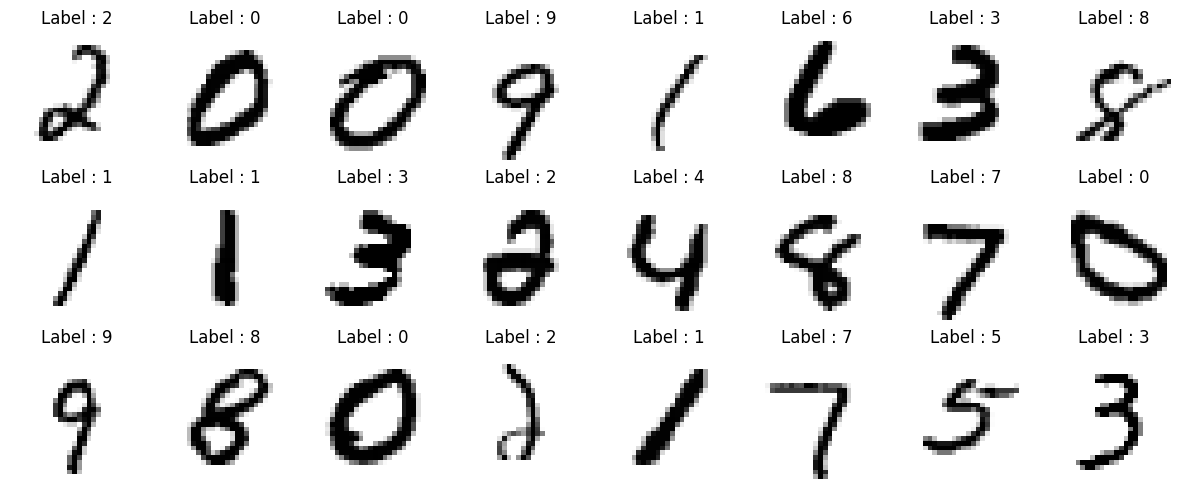

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for ax in axes.flat:
    i = np.random.randint(len(X_train))
    # ax.imshow(X_train[i], cmap="gray") gray, cool, hot, plasma, inferno, viridis
    ax.imshow(X_train[i], cmap="gray_r")
    ax.set_title(f"Label : {y_train[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

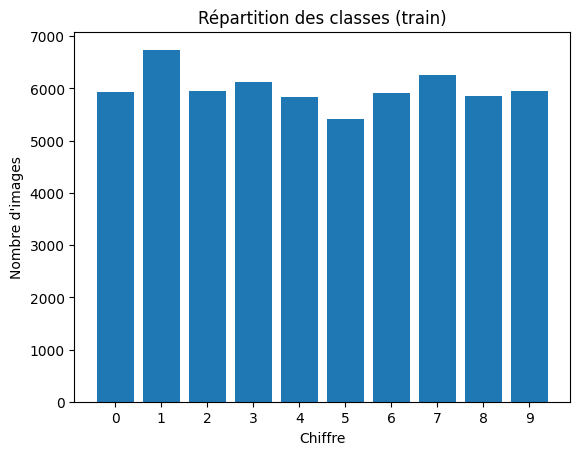

In [7]:
# Équilibre des classes
classes, counts = np.unique(y_train, return_counts=True)
plt.bar(classes, counts)
plt.xticks(classes)
plt.xlabel("Chiffre"); plt.ylabel("Nombre d'images")
plt.title("Répartition des classes (train)")
plt.show()

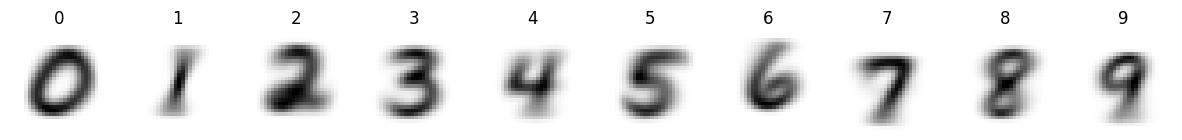

In [8]:
# Image moyenne par classe : montre la "forme type" de chaque chiffre
# y_train == c : Crée un masque booléen de taille (60000,) - True partout où l'étiquette correspond au chiffre c, et False ailleurs.
# X_train[y_train == c] : Filtre le grand tableau d'images pour ne conserver que celles qui représentent ce chiffre précis.
#
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c in range(10):
    axes[c].imshow(X_train[y_train == c].mean(axis=0), cmap="gray_r")
    axes[c].set_title(str(c)); axes[c].axis("off")
plt.show()

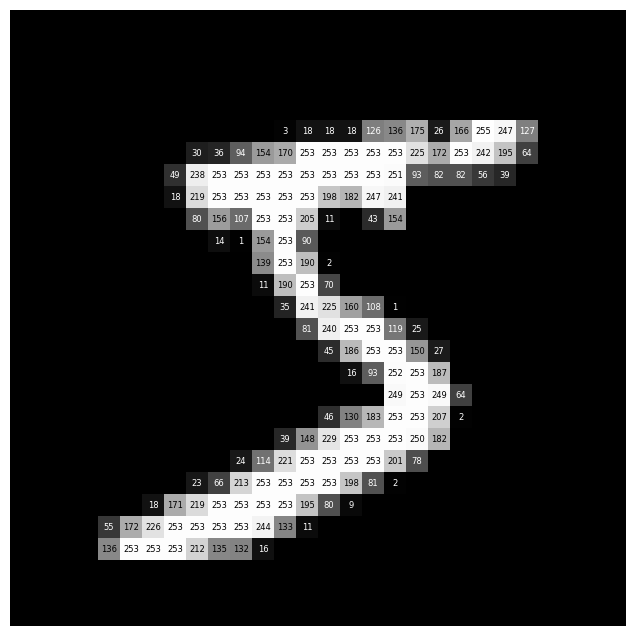

In [9]:
plt.figure(figsize=(8, 8))
plt.imshow(X_train[0], cmap="gray")
for i in range(28):
    for j in range(28):
        v = X_train[0][i, j]
        if v > 0:
            plt.text(j, i, v, ha="center", va="center", fontsize=6,
                     color="black" if v > 128 else "white")
plt.axis("off"); plt.show()

# **Entraînement et Évaluation de la Baseline**
On utilise deux modèles contrastés :
1.  La Régression Logistique : Modèle linéaire simple, rapide, qui sert de point de référence robuste.
2. La Forêt Aléatoire (Random Forest) : Modèle non linéaire basé sur des arbres de décision, capable de capturer des interactions locales entre pixels.

## I. **Normalisation**

- Les pixels MNIST sont stockés en uint8 (entiers de 0 à 255). Or les modèles travaillent avec des nombres décimaux : la division produit des fractions, qui ne tiennent pas dans un entier. float32 suffit en précision et prend deux fois moins de mémoire que float64.

- La division par 255 ramène chaque pixel de l’intervalle [0, 255] à [0, 1]. C’est ce qu’on appelle la normalisation (ou mise à l’échelle). Elle sert à :
    - Faciliter l’optimisation : des features de même échelle donnent une fonction de perte mieux conditionnée, donc une convergence plus rapide et plus stable (c’est exactement ce qui posait problème avec saga).
    - Éviter que de grandes valeurs dominent les calculs, par exemple dans les exponentielles du softmax, qui peuvent déborder.
    - Rendre la régularisation cohérente : Cela agit sur des poids dont l’ordre de grandeur est raisonnable.

In [10]:
# Conversion en float et normalisation
X_train_scaled = X_train.astype('float32') / 255.0

- Il est crucial de mélanger (shuffler) les données avant de trancher, car le MNIST d'origine est souvent trié par classe (tous les 0 d'abord, puis tous les 1, etc.).

In [11]:
# Création d'un tableau d'indices mélangés aléatoirement
indices = np.arange(len(X_train_scaled))
np.random.seed(42)  # Pour la reproductibilité
np.random.shuffle(indices)

# Application du mélange sur les images et les labels
X_train_shuffled = X_train_scaled[indices]
y_train_shuffled = y_train[indices]

# 3. Découpage (ex: 50 000 pour le train, 10 000 pour la validation)
split_idx = 6000

X_val, y_val = X_train_shuffled[:split_idx], y_train_shuffled[:split_idx]
X_tr, y_tr = X_train_shuffled[split_idx:], y_train_shuffled[split_idx:]


In [12]:
print("Train :", X_tr.shape, y_tr.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test  :", X_test.shape, y_test.shape)

Train : (54000, 28, 28) (54000,)
Val  : (6000, 28, 28) (6000,)
Test  : (10000, 28, 28) (10000,)


LogisticRegression (comme la plupart des modèles scikit-learn) attend en entrée une matrice 2D de forme (n_échantillons, n_features) : une ligne par exemple, une colonne par caractéristique.

- Une image MNIST fait 28 × 28 pixels, donc un tableau (N, 28, 28) a trois dimensions : le modèle ne sait pas quoi faire de cette structure, il lui faut un vecteur de features par image.
- On « déroule » donc chaque image en une ligne de 28 × 28 = 784 valeurs, une par pixel.

In [16]:
# Aplatissement des tenseurs 3D (N, 28, 28) vers des matrices 2D (N, 784)
X_tr_flat = X_tr.reshape(X_tr.shape[0], -1).astype('float32')
X_val_flat = X_val.reshape(X_val.shape[0], -1).astype('float32')

print("Nouvelle forme de X_tr :", X_tr_flat.shape)
print("Nouvelle forme de X_val :", X_val_flat.shape)

Nouvelle forme de X_tr : (54000, 784)
Nouvelle forme de X_val : (6000, 784)


In [19]:
import numpy as np
print(np.min(X_tr_flat), np.max(X_tr_flat))

0.0 1.0


Remarque : La régression logistique traite alors chaque pixel comme une feature indépendante : elle ne sait plus que deux pixels sont voisins. La structure spatiale est ignorée. C’est l’une des raisons pour lesquelles les réseaux convolutifs (CNN), qui travaillent directement sur les images 2D, font mieux que ce type de modèle sur MNIST.

## II. **Entraînement**

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
# matrice de confusion
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.xlabel('Prédictions')
    plt.ylabel('Vraies étiquettes (Ground Truth)')
    plt.title(title)
    plt.show()

### A. **Régression logistique**

Si on évalue sur le train, le modèle pourrait simplement avoir mémorisé les données (surapprentissage) et afficher un score excellent sans être utile sur de nouvelles images. L’accuracy sur la validation est donc une estimation honnête de la performance réelle.

In [20]:
# Modèle 1 : Régression Logistique ---
print("--- Entraînement de la Régression Logistique ---")
# max_iter augmenté car MNIST demande un peu de temps de convergence pour l'optimiseur
lr_model = LogisticRegression(max_iter=100, random_state=42, n_jobs=-1)
lr_model.fit(X_tr_flat, y_tr)

# Prédiction sur la validation
y_pred_lr = lr_model.predict(X_val_flat)
acc_lr = accuracy_score(y_val, y_pred_lr)
print(f"Précision (Validation) - Régression Logistique : {acc_lr * 100:.2f}%\n")

--- Entraînement de la Régression Logistique ---
Précision (Validation) - Régression Logistique : 92.70%



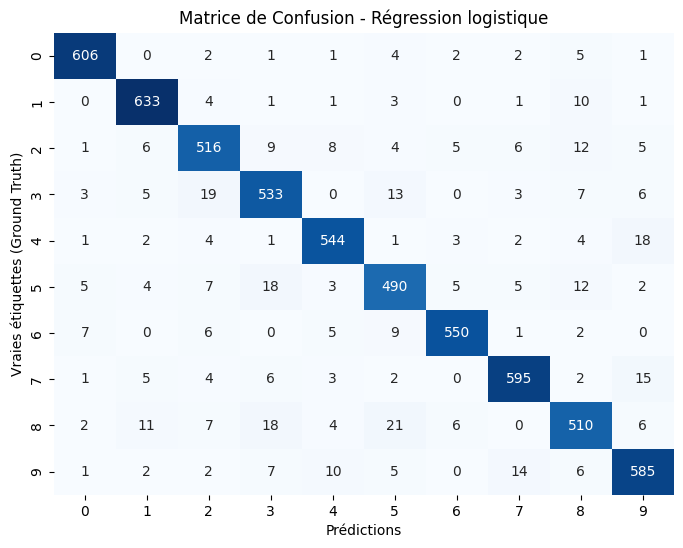

In [ ]:
plot_confusion_matrix(y_val, y_pred_lr, "Matrice de Confusion - Régression logistique")

##### Un **solver** est l’algorithme d’optimisation qui cherche les meilleurs paramètres (poids) du modèle en minimisant la fonction de perte. Pour la régression logistique, il n’existe pas de formule directe : le solver ajuste les poids pas à pas, de manière itérative, jusqu’à convergence.

Si l'on élargit aux algorithmes d'optimisation mathématique et d'apprentissage automatique connexes (utilisés pour des problèmes similaires ou dans des modules complémentaires comme SciPy / SGDClassifier), on peut en regrouper 8 majeurs :

- **lbfgs** : Le solveur par défaut de Scikit-Learn (basé sur une approximation quasi-Newton). Idéal pour les jeux de données denses et de taille moyenne.

- **liblinear** : Basé sur la descente par coordonnées (Coordinate Descent), très performant pour les petits jeux de données ou les matrices creuses (sparse).

- **newton-cg** : Utilise la méthode de Newton avec un gradient conjugué, en calculant (ou approchant) la matrice hessienne (secondes dérivées).  

- **newton-cholesky** : Une variante optimisée de la méthode de Newton basée sur la factorisation de Cholesky, particulièrement performante lorsque le nombre d'échantillons est très supérieur au nombre de caractéristiques.

- **sag** (Stochastic Average Gradient) : Variante stochastique conçue pour accélérer la convergence sur les très grands volumes de données (limité à la pénalité L2).

- **saga** (Stochastic Average Gradient Augmented) : Une évolution du sag qui supporte en plus la régularisation L1 et Elastic-Net.

- **cg** (Conjugate Gradient) : Un algorithme d'optimisation itératif généraliste (disponible dans SciPy) pour minimiser des fonctions de coût quadratiques ou non linéaires.

- **sgd** (Stochastic Gradient Descent) : Utilisé via le SGDClassifier de Scikit-Learn pour implémenter une régression logistique par descente de gradient stochastique pure, idéale pour l'apprentissage en continu (online learning) sur des masses de données gigantesques.

### B. **Random Forest**

In [ ]:
# Modèle 1 : Forêt Aléatoire ---
print("--- Entraînement de la Forêt Aléatoire ---")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_tr_flat, y_tr)

# Prédiction sur la validation
y_pred_rf = rf_model.predict(X_val_flat)
acc_rf = accuracy_score(y_val, y_pred_rf)
print(f"Précision (Validation) - Forêt Aléatoire : {acc_rf * 100:.2f}%\n")

--- Entraînement de la Forêt Aléatoire ---
Précision (Validation) - Forêt Aléatoire : 97.20%



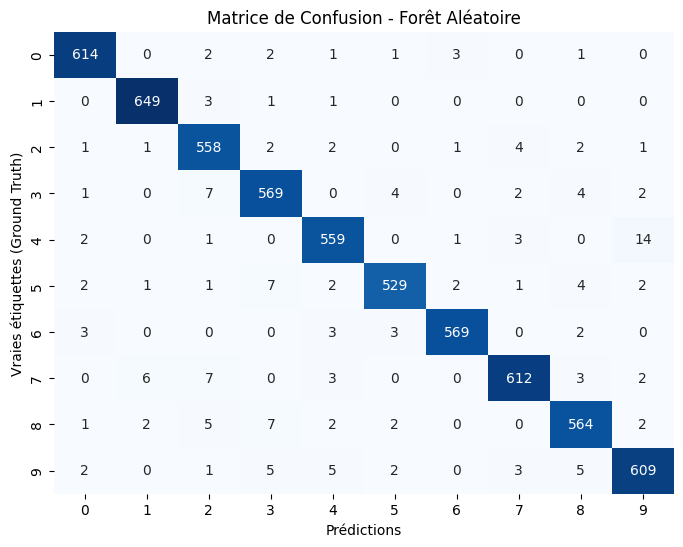

In [ ]:
plot_confusion_matrix(y_val, y_pred_rf, "Matrice de Confusion - Forêt Aléatoire")